# Taller · Limpieza y análisis de datos con pandas

**Minicurso «Introducción al análisis de datos con Python»** · Universidad Nacional de Colombia · Facultad de Minas · Sede Medellín

**Versión con soluciones.** Todas las celdas están completas y ejecutadas: úsala para revisar tu trabajo.

## Antes de empezar: abre el taller en Google Colab

1. Entra a [colab.research.google.com](https://colab.research.google.com) con tu cuenta de Google.
2. Menú **Archivo → Subir cuaderno** (*File → Upload notebook*) y elige `taller_solucion.ipynb`.
3. En la barra de la izquierda haz clic en el ícono de carpeta (**Archivos**) y arrastra `domicilios_sucio.csv` a ese panel. Colab avisa que los archivos subidos se borran al cerrar la sesión: está bien.
4. Ejecuta las celdas de arriba hacia abajo con **Shift + Enter**.

Si una celda falla porque la ejecutaste dos veces o en desorden, usa **Entorno de ejecución → Ejecutar anteriores** (*Runtime → Run before*) y vuelve a intentarlo. Si Colab se reinició y `domicilios_sucio.csv` ya no aparece en el panel de archivos, vuelve a arrastrarlo antes de ejecutar.

Si te atrasas, no te preocupes: al comienzo de «Análisis gráfico» hay un **punto de control** para seguir con la base ya limpia.

## El caso

«Pan de Datos» es una panadería **ficticia** con servicio a domicilio en el Valle de Aburrá. Cada fila del archivo es un pedido de 2025. Los datos son **sintéticos**: se crearon para este curso y no son cifras reales.

## Preparación

Importamos pandas con su apodo de siempre, `pd`. Las gráficas también salen de pandas (`.plot`), que usa matplotlib por dentro.

In [1]:
import pandas as pd

## Paso E · Extraer: leer el archivo

**Problema:** el archivo separa las columnas con `;` y usa coma decimal (`7,1`), como Excel en Colombia, pero `read_csv` espera comas.

**Diagnóstico:** `df.head()` y `df.shape` · **Método:** `pd.read_csv('domicilios_sucio.csv', sep=';', decimal=',')`

**Error común:** leer el archivo sin decirle a pandas cuál es el separador. Ejecuta y mira qué pasa.

In [2]:
df = pd.read_csv('domicilios_sucio.csv')
df.head()

,ID Pedido; Fecha;Municipio ;PRODUCTO;Cantidad;Precio Unitario;Metodo Pago;Distancia KM;Tiempo Entrega;Edad Cliente;Calificacion
1001;03/01/2025;Bello;Almojábana;5;$2.800;Nequi;7,1;64;23;4
1002;03/01/2025;Bello;Jugo natural;2;$6.000;Tarjeta;5,9;34;36;4
1003;03/01/2025;Medellín;Pan de bono;1;$2.500;tarjeta;2,6;16;24;5
1004;03/01/2025;Bello;Jugo natural;4;$6.000;Nequi;6,8;47;67;4
1005;04/01/2025;Envigado;Café;3;$3.200;Daviplata;3,3;23;40;5


In [3]:
df.shape

(1250, 1)

Todo quedó amontonado en **una sola columna**. Ahora sí, con el separador y el decimal correctos:

In [4]:
df = pd.read_csv('domicilios_sucio.csv', sep=';', decimal=',')
df.head()

,ID Pedido,Fecha,Municipio,PRODUCTO,Cantidad,Precio Unitario,Metodo Pago,Distancia KM,Tiempo Entrega,Edad Cliente,Calificacion
0,1001,03/01/2025,Bello,Almojábana,5,$2.800,Nequi,7.1,64,23.0,4
1,1002,03/01/2025,Bello,Jugo natural,2,$6.000,Tarjeta,5.9,34,36.0,4
2,1003,03/01/2025,Medellín,Pan de bono,1,$2.500,tarjeta,2.6,16,24.0,5
3,1004,03/01/2025,Bello,Jugo natural,4,$6.000,Nequi,6.8,47,67.0,4
4,1005,04/01/2025,Envigado,Café,3,$3.200,Daviplata,3.3,23,40.0,5


In [5]:
df.shape

(1250, 11)

## Paso 1 · Nombres de columnas

**Problema:** los encabezados traen espacios, mayúsculas y espacios internos (`' Fecha'`, `'Municipio '`, `'Precio Unitario'`): así es muy fácil escribirlos mal.

**Diagnóstico:** `df.columns` · **Método:** `.str.strip().str.lower().str.replace(' ', '_')`

In [6]:
df.columns

Index(['ID Pedido', ' Fecha', 'Municipio ', 'PRODUCTO', 'Cantidad',
       'Precio Unitario', 'Metodo Pago', 'Distancia KM', 'Tiempo Entrega',
       'Edad Cliente', 'Calificacion'],
      dtype='object')

In [7]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['id_pedido', 'fecha', 'municipio', 'producto', 'cantidad',
       'precio_unitario', 'metodo_pago', 'distancia_km', 'tiempo_entrega',
       'edad_cliente', 'calificacion'],
      dtype='object')

## Paso 2 · Filas duplicadas

**Problema:** algunos pedidos quedaron registrados dos veces; si no los quitamos, contamos doble.

**Diagnóstico:** `df.duplicated().sum()` · **Método:** `df.drop_duplicates()`

Si el conteo aparece como `np.int64(...)`, es simplemente un número entero.

In [8]:
df.duplicated().sum()

np.int64(40)

In [9]:
df = df.drop_duplicates()
df.shape

(1210, 11)

## Paso 3 · Texto inconsistente

**Problema:** el mismo municipio aparece escrito de muchas formas (`medellin`, `MEDELLIN`, `' Medellín '`, `Itagui`…) y pandas cuenta cada una por aparte.

**Diagnóstico:** `value_counts()` · **Método:** `.str.strip().str.title()` y luego `.replace({...})`

Para mirar la tabla usa `df.head()`. Si en algún momento aparece un aviso rosado `SettingWithCopyWarning`, no es un error: el resultado es el mismo.

In [10]:
df['municipio'].value_counts()

municipio
Medellín      391
Envigado      165
Bello         125
Itagüí        111
Sabaneta      105
medellin       41
MEDELLIN       33
Medellin       29
Itagui         28
 Medellín      26
BELLO          24
ENVIGADO       23
itagui         21
SABANETA       19
envigado       18
ITAGUI         16
bello          14
medellín       12
sabaneta        9
Name: count, dtype: int64

`strip()` quita los espacios de los extremos y `title()` deja solo la primera letra en mayúscula. Como `title()` no pone tildes, `replace` cambia `Medellin` por `Medellín` e `Itagui` por `Itagüí`.

In [11]:
df['municipio'] = df['municipio'].str.strip().str.title()
df['municipio'] = df['municipio'].replace({'Medellin': 'Medellín', 'Itagui': 'Itagüí'})

In [12]:
df['municipio'].value_counts()

municipio
Medellín    532
Envigado    206
Itagüí      176
Bello       163
Sabaneta    133
Name: count, dtype: int64

Lo mismo pasa con el método de pago (`nequi`, `NEQUI`, `'Nequi '`…). Aquí bastan `strip()` y `title()`. Fíjate en que `Nequi` sale dos veces en el conteo: una de las dos trae un espacio invisible al final (`'Nequi '`). Por eso `strip()` va primero.

In [13]:
df['metodo_pago'].value_counts()

metodo_pago
Nequi        347
Efectivo     244
Tarjeta      183
Daviplata    108
nequi         62
efectivo      37
NEQUI         35
EFECTIVO      31
tarjeta       30
DaviPlata     25
Nequi         22
TARJETA       20
daviplata     17
DAVIPLATA     13
Name: count, dtype: int64

In [14]:
df['metodo_pago'] = df['metodo_pago'].str.strip().str.title()
df['metodo_pago'].value_counts()

metodo_pago
Nequi        466
Efectivo     312
Tarjeta      233
Daviplata    163
Name: count, dtype: int64

## Paso 4 · Números guardados como texto

**Problema:** `precio_unitario` llegó como texto (`$2.800`), con signo y punto de miles; así no se puede sumar ni multiplicar.

**Diagnóstico:** `df.dtypes` · **Método:** `.str.replace('$', '')`, `.str.replace('.', '')` y `pd.to_numeric()`

In [15]:
df.dtypes

id_pedido            int64
fecha               object
municipio           object
producto            object
cantidad             int64
precio_unitario     object
metodo_pago         object
distancia_km       float64
tiempo_entrega       int64
edad_cliente       float64
calificacion         int64
dtype: object

En `df.dtypes`, `object` significa texto (en pandas 3 aparece como `str`). Primero quitamos el `$`, después el punto de miles y al final convertimos a número.

In [16]:
df['precio_unitario'] = df['precio_unitario'].str.replace('$', '')
df['precio_unitario'] = df['precio_unitario'].str.replace('.', '')
df['precio_unitario'] = pd.to_numeric(df['precio_unitario'])

In [17]:
df.dtypes

id_pedido            int64
fecha               object
municipio           object
producto            object
cantidad             int64
precio_unitario    float64
metodo_pago         object
distancia_km       float64
tiempo_entrega       int64
edad_cliente       float64
calificacion         int64
dtype: object

## Paso 5 · Fechas como texto

**Problema:** `fecha` también es texto (`03/01/2025`); como texto no se puede sacar el mes ni ordenar en el tiempo.

**Método:** `pd.to_datetime(df['fecha'], format='%d/%m/%Y')` (día/mes/año) y luego `.dt.month`. De paso creamos `total` = cantidad × precio.

**Comprobación:** `df.head()`. La columna `fecha` debe verse como `2025-01-03` y al final deben aparecer `mes` y `total`.

In [18]:
df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y')
df['mes'] = df['fecha'].dt.month
df['total'] = df['cantidad'] * df['precio_unitario']

In [19]:
df.head()

,id_pedido,fecha,municipio,producto,cantidad,precio_unitario,metodo_pago,distancia_km,tiempo_entrega,edad_cliente,calificacion,mes,total
0,1001,2025-01-03,Bello,Almojábana,5,2800.0,Nequi,7.1,64,23.0,4,1,14000.0
1,1002,2025-01-03,Bello,Jugo natural,2,6000.0,Tarjeta,5.9,34,36.0,4,1,12000.0
2,1003,2025-01-03,Medellín,Pan de bono,1,2500.0,Tarjeta,2.6,16,24.0,5,1,2500.0
3,1004,2025-01-03,Bello,Jugo natural,4,6000.0,Nequi,6.8,47,67.0,4,1,24000.0
4,1005,2025-01-04,Envigado,Café,3,3200.0,Daviplata,3.3,23,40.0,5,1,9600.0


## Paso 6 · Datos faltantes

**Problema:** hay celdas vacías (`NaN`) en el método de pago, el precio y la edad del cliente.

**Diagnóstico:** `df.isna().sum()` · **Método:** `fillna('Sin dato')` y `dropna(subset=['precio_unitario'])`

In [20]:
df.isna().sum()

id_pedido           0
fecha               0
municipio           0
producto            0
cantidad            0
precio_unitario    12
metodo_pago        36
distancia_km        0
tiempo_entrega      0
edad_cliente       60
calificacion        0
mes                 0
total              12
dtype: int64

Cada columna se trata distinto. Al método de pago le ponemos `'Sin dato'`, porque el pedido sí ocurrió. Sin precio no hay total de venta, así que quitamos esas filas. La **edad se deja vacía**: pandas ignora los vacíos al promediar y al graficar, y borrar esas filas haría perder pedidos válidos.

In [21]:
df['metodo_pago'] = df['metodo_pago'].fillna('Sin dato')
df = df.dropna(subset=['precio_unitario'])
df.shape

(1198, 13)

In [22]:
df.isna().sum()

id_pedido           0
fecha               0
municipio           0
producto            0
cantidad            0
precio_unitario     0
metodo_pago         0
distancia_km        0
tiempo_entrega      0
edad_cliente       60
calificacion        0
mes                 0
total               0
dtype: int64

## Paso 7 · Valores imposibles

**Problema:** hay tiempos de entrega negativos, de 0 o de 999 minutos, y calificaciones de 0, 10 o 45, cuando la escala va de 1 a 5.

**Diagnóstico:** `df.describe()` (mira las filas `min` y `max`) · **Método:** `between()`

In [23]:
df.describe()

,id_pedido,fecha,cantidad,precio_unitario,distancia_km,tiempo_entrega,edad_cliente,calificacion,mes,total
count,1198.000000,1198,1198.000000,1198.000000,1198.000000,1198.00000,1138.000000,1198.00000,1198.000000,1198.000000
mean,1605.590985,2025-07-19 03:47:10.717862912,2.726210,4107.011686,4.953005,34.95409,34.492970,4.53005,7.079299,11062.353923
min,1001.000000,2025-01-03 00:00:00,1.000000,2000.000000,0.600000,-15.00000,15.000000,0.00000,1.000000,2000.000000
25%,1304.250000,2025-04-20 06:00:00,2.000000,2500.000000,3.400000,23.00000,22.000000,4.00000,4.000000,5000.000000
50%,1605.500000,2025-07-18 12:00:00,2.000000,2800.000000,4.900000,30.00000,34.000000,5.00000,7.000000,8400.000000
75%,1906.750000,2025-10-23 00:00:00,4.000000,6000.000000,6.200000,37.00000,44.000000,5.00000,10.000000,13500.000000
max,2210.000000,2025-12-31 00:00:00,6.000000,9500.000000,11.200000,999.00000,75.000000,45.00000,12.000000,57000.000000
std,348.911550,NaN,1.482337,2420.933680,2.011546,57.22494,14.242789,1.83815,3.484716,9265.345471


`between(1, 180)` marca con `True` las filas cuyo valor está entre 1 y 180 (incluidos) y `df[...]` se queda solo con esas. Tres horas es un límite generoso para un domicilio.

In [24]:
df = df[df['tiempo_entrega'].between(1, 180)]
df = df[df['calificacion'].between(1, 5)]
df.shape

(1180, 13)

In [25]:
df.describe()

,id_pedido,fecha,cantidad,precio_unitario,distancia_km,tiempo_entrega,edad_cliente,calificacion,mes,total
count,1180.000000,1180,1180.000000,1180.000000,1180.000000,1180.000000,1120.000000,1180.000000,1180.000000,1180.000000
mean,1606.439831,2025-07-19 10:11:23.389830400,2.725424,4108.644068,4.952458,31.883898,34.474107,4.463559,7.088136,11048.135593
min,1001.000000,2025-01-03 00:00:00,1.000000,2000.000000,0.600000,10.000000,15.000000,2.000000,1.000000,2000.000000
25%,1305.750000,2025-04-21 00:00:00,2.000000,2500.000000,3.400000,23.000000,22.000000,4.000000,4.000000,5000.000000
50%,1606.500000,2025-07-19 00:00:00,2.000000,2800.000000,4.900000,30.000000,34.000000,5.000000,7.000000,8400.000000
75%,1906.250000,2025-10-23 00:00:00,4.000000,6000.000000,6.200000,37.000000,44.000000,5.000000,10.000000,13500.000000
max,2210.000000,2025-12-31 00:00:00,6.000000,9500.000000,11.200000,98.000000,75.000000,5.000000,12.000000,57000.000000
std,348.408592,NaN,1.485308,2422.518025,2.013926,12.373571,14.260667,0.714228,3.477644,9256.400756


## Paso L · Cargar: guardar la base limpia

**Problema:** la base limpia solo vive en la memoria de Colab; hay que revisarla y guardarla en un archivo nuevo.

**Diagnóstico:** `df.info()` · **Método:** `df.to_csv('domicilios_limpio.csv', index=False)`

In [26]:
df.info()
df.to_csv('domicilios_limpio.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
Index: 1180 entries, 0 to 1249
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_pedido        1180 non-null   int64         
 1   fecha            1180 non-null   datetime64[ns]
 2   municipio        1180 non-null   object        
 3   producto         1180 non-null   object        
 4   cantidad         1180 non-null   int64         
 5   precio_unitario  1180 non-null   float64       
 6   metodo_pago      1180 non-null   object        
 7   distancia_km     1180 non-null   float64       
 8   tiempo_entrega   1180 non-null   int64         
 9   edad_cliente     1120 non-null   float64       
 10  calificacion     1180 non-null   int64         
 11  mes              1180 non-null   int32         
 12  total            1180 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int32(1), int64(4), object(3)
memory usage: 124.5+ KB


`domicilios_limpio.csv` aparece en el panel de archivos (a veces hay que actualizarlo). Para conservarlo: clic derecho sobre el archivo → **Descargar**. `index=False` evita guardar el índice como una columna más.

Es un archivo pensado para pandas: separa con comas y usa punto decimal. Si lo abres con doble clic en un Excel en español, todo queda en una sola columna; en Excel se abre con **Datos → Desde texto/CSV**.

# Análisis gráfico

Con la base limpia respondemos cinco preguntas de negocio. Cada gráfica es una sola instrucción de pandas (`.plot`), partida en renglones para que se lea mejor. El único concepto nuevo es `groupby`: agrupar y resumir.

Encima de cada gráfica aparece un texto como `<Axes: ...>`: es normal, es el objeto que devuelve pandas. Tus gráficas se verán con el estilo por defecto de Colab, que cambia la letra, el tamaño y el marco: los datos y la forma son los mismos que en la presentación.

## Punto de control

**Solo si te atrasaste, si algo falló o si Colab se reinició.** Sube `domicilios_limpio.csv` (carpeta *respaldo* del enlace del taller) al panel de archivos, ejecuta la celda `import pandas as pd` del comienzo y luego la celda siguiente: debe mostrar `(1180, 13)`.

Si llegaste bien hasta aquí, puedes saltarla. Ejecutarla tampoco daña nada: lee el archivo que acabas de guardar en el paso L.

In [27]:
df = pd.read_csv('domicilios_limpio.csv')
df.shape

(1180, 13)

## Gráfica 1 · ¿Qué productos se piden más?

**Gráfica:** barras horizontales · **Método:** `value_counts().plot(kind='barh')`

<Axes: title={'center': 'Pedidos por producto'}, ylabel='producto'>

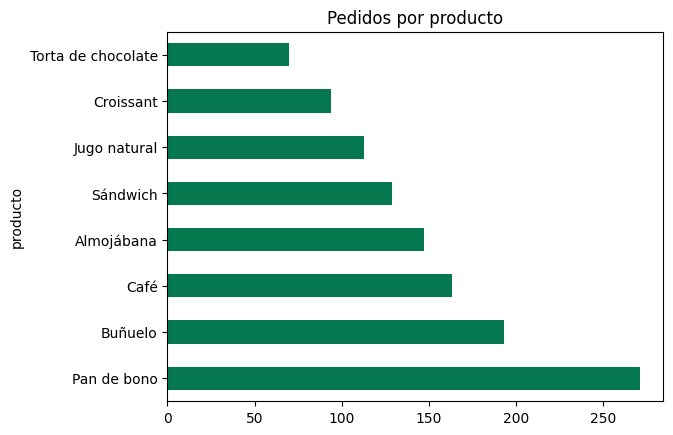

In [28]:
df['producto'].value_counts().plot(
    kind='barh', title='Pedidos por producto', color='#06784F')

## Gráfica 2 · ¿Cómo cambian las ventas durante el año?

**Gráfica:** línea · **Método:** `groupby('mes')['total'].sum()` agrupa los pedidos por mes y suma sus ventas. El `1e6` encima del eje significa «millones».

<Axes: title={'center': 'Ventas por mes'}, xlabel='mes', ylabel='Pesos'>

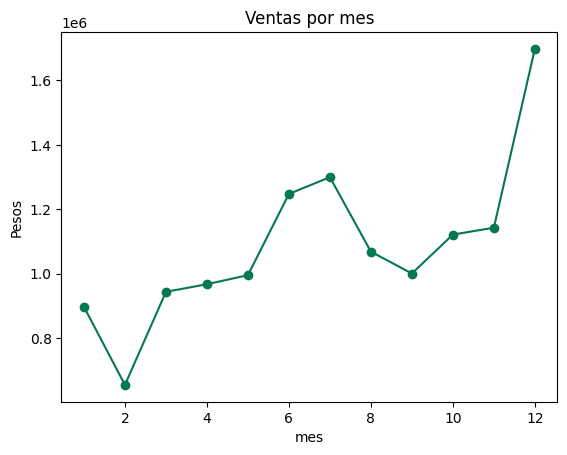

In [29]:
df.groupby('mes')['total'].sum().plot(
    kind='line', marker='o', color='#06784F',
    title='Ventas por mes', ylabel='Pesos')

## Gráfica 3 · ¿Quiénes son nuestros clientes?

**Gráfica:** histograma de la edad · **Método:** `plot(kind='hist', bins=20)`. Los pedidos sin edad simplemente no se cuentan.

<Axes: title={'center': 'Edad de los clientes'}, ylabel='Pedidos'>

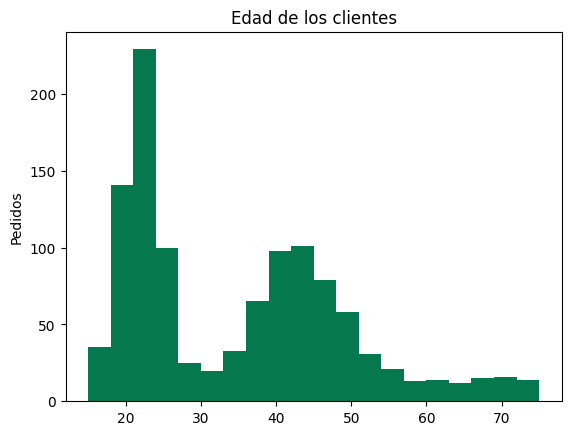

In [30]:
df['edad_cliente'].plot(
    kind='hist', bins=20, color='#06784F',
    title='Edad de los clientes', ylabel='Pedidos')

## Gráfica 4 · ¿Tardamos más cuando el pedido va más lejos?

**Gráfica:** dispersión · **Método:** `df.plot(kind='scatter', x=..., y=...)`

<Axes: title={'center': 'Distancia contra tiempo de entrega'}, xlabel='distancia_km', ylabel='tiempo_entrega'>

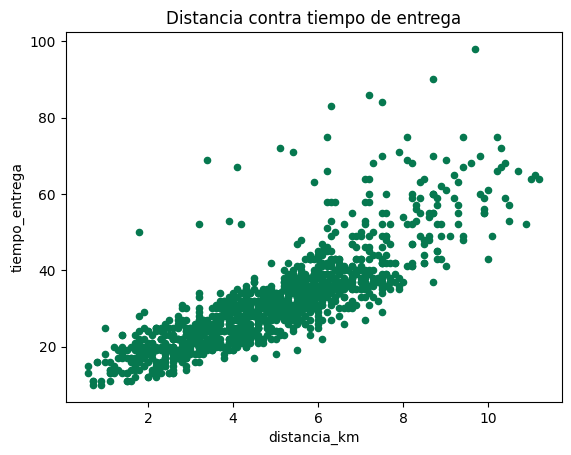

In [31]:
df.plot(
    kind='scatter', x='distancia_km', y='tiempo_entrega',
    title='Distancia contra tiempo de entrega', color='#06784F')

## Gráfica 5 · ¿Dónde se demoran más los domicilios?

**Gráfica:** caja y bigotes · **Método:** `df.boxplot(column=..., by=...)`. pandas agrega por su cuenta un título en inglés («Boxplot grouped by municipio»): no es un error.

<Axes: title={'center': 'tiempo_entrega'}, xlabel='municipio'>

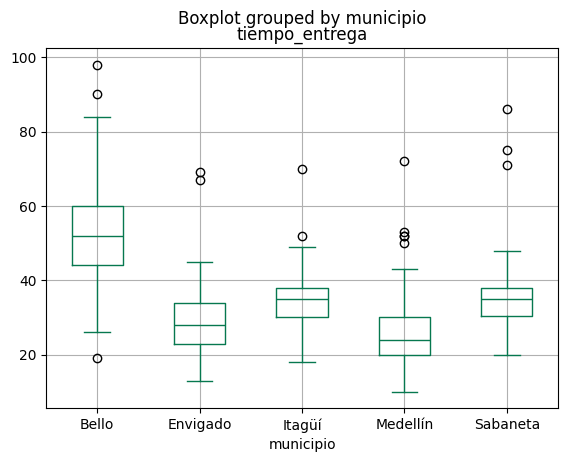

In [32]:
df.boxplot(column='tiempo_entrega', by='municipio', color='#06784F')

## Reto opcional · ¿Califican peor cuando el domicilio tarda más?

Calcula el tiempo promedio de entrega para cada calificación y grafícalo en barras. **Pista:** es como la gráfica 2, pero se agrupa por `calificacion`, se resume `tiempo_entrega` y se usa `mean()` (promedio) en lugar de `sum()`.

<Axes: title={'center': 'Minutos promedio de entrega por calificación'}, ylabel='calificacion'>

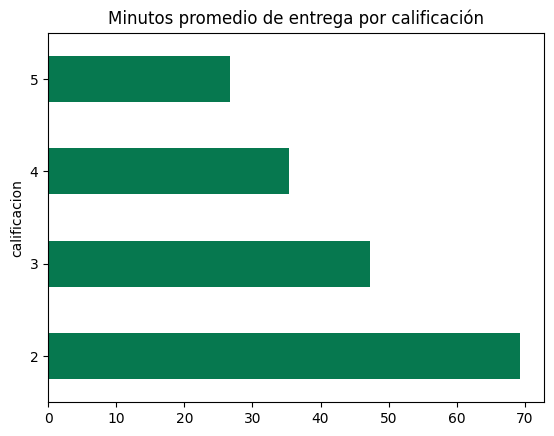

In [33]:
df.groupby('calificacion')['tiempo_entrega'].mean().plot(
    kind='barh', color='#06784F',
    title='Minutos promedio de entrega por calificación')

## Para seguir aprendiendo

- Documentación de pandas: [pandas.pydata.org/docs](https://pandas.pydata.org/docs/)
- Kaggle Learn, cursos gratuitos de pandas y visualización: [kaggle.com/learn](https://www.kaggle.com/learn)
- Google Colab: [colab.research.google.com](https://colab.research.google.com)